In [2]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import statsmodels.formula.api as smf
from itertools import product
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay,
)
from itertools import combinations
from scipy import sparse
from threadpoolctl import threadpool_limits

SEED = 42
SAMPLE_FRACTION = 1  # 0.05%
DATA_PATH = "datasets/NOAA_Weather/weather_cleaned.parquet"


Our data from 2008-2025 is about 1.5M entries. To enable effective modelling we sampled only 0.05% of it. Using a SEED to ensure reproducibility.

In [3]:
parquet = pq.ParquetFile(DATA_PATH)
sample_size = round(parquet.metadata.num_rows * SAMPLE_FRACTION)
rng = np.random.default_rng(SEED)
positions = np.sort(rng.choice(parquet.metadata.num_rows, sample_size, replace=False))

parts = []
offset = 0
for group in range(parquet.num_row_groups):
    end = offset + parquet.metadata.row_group(group).num_rows
    rows = positions[(positions >= offset) & (positions < end)] - offset
    if len(rows):
        table = parquet.read_row_group(group)
        parts.append(table.take(rows).to_pandas())
    offset = end
sample = pd.concat(parts, ignore_index=True)
print(f"Sample: {len(sample):,} flights")

Sample: 5,828,408 flights


In [4]:
model_data = sample.loc[sample['airport_code']=='ORD'].copy()


## 1. Regression Model

We will use multiple linear regression to predict the temperature at Chicago O'Hare Airport (ORD) one hour ahead. First we look at the Temperature Distrubution at ORD. The distibution looks like 2 curves joined into 1. 




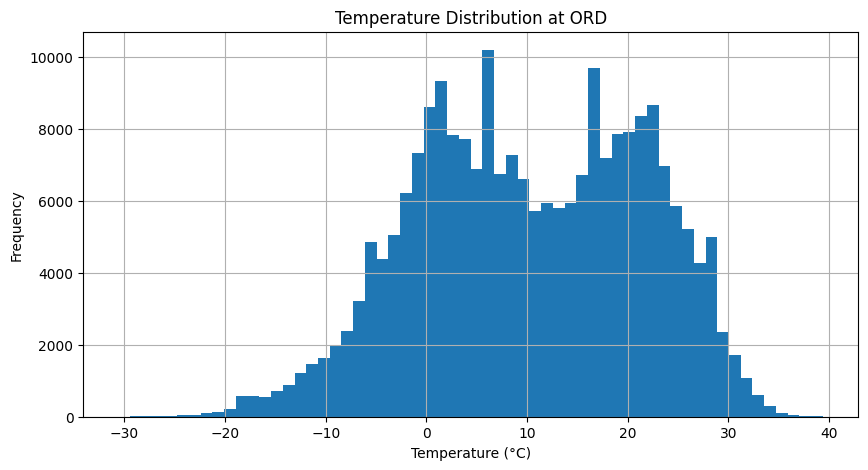

In [5]:
import matplotlib.pyplot as plt

model_data['temperature_c'].hist(bins=60, figsize=(10, 5))

plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.title("Temperature Distribution at ORD")
plt.show()

Our dependent variable is the temperature during the next hour:

$$
Y_{t+1} = T_{t+1}
$$

We will start with the following linear regression model:

$$
T_{t+1} = \beta_0 + \beta_1 T_t + \beta_2 D_t + \beta_3 W_t + \beta_4 P_t + \text{Month Effects} + \text{Hour Effects} + \epsilon
$$

Where:

| Variable | Description |
|---|---|
| $T_t$ | Current temperature (°C) |
| $D_t$ | Current dew point (°C) |
| $W_t$ | Current wind speed (m/s) |
| $P_t$ | Current sea-level pressure (hPa) |
| Month Effects | Seasonal temperature differences |
| Hour Effects | Daily temperature patterns |
| $\epsilon$ | Unexplained variation |

We will exclude relative humidity initially because it can be calculated from temperature and dew point. This helps reduce redundant predictors.

Our goal is to determine whether these atmospheric conditions improve next-hour temperature predictions compared with simply using the current temperature.

In [6]:


# Use the cleaned dataset
df = model_data.copy()

df["timestamp_utc"] = pd.to_datetime(
    df["timestamp_utc"], utc=True
)

df = df.sort_values("timestamp_utc")

# Keep the last observation in each hour
df["hour_utc"] = df["timestamp_utc"].dt.floor("h")
df = df.drop_duplicates("hour_utc", keep="last")

# Preserve missing hourly intervals
df = df.set_index("hour_utc").asfreq("h")

# Create next-hour temperature target
df["temperature_next_hour"] = df["temperature_c"].shift(-1)

# Calendar features in Chicago local time
local_time = df.index.tz_convert("America/Chicago")
df["month"] = local_time.month
df["hour_of_day"] = local_time.hour

# Require observed current and future temperatures
df = df.dropna(
    subset=["temperature_c", "temperature_next_hour"]
)

print("Observations:", len(df))


Observations: 157623


In [7]:
df

,station_id,station_name,timestamp_utc,latitude,longitude,elevation_m,temperature_c,temperature_c_measurement_code,temperature_c_qc,temperature_c_report_type,...,ceiling_height_m_review,sea_level_pressure_hpa_qc_status,sea_level_pressure_hpa_invalid,sea_level_pressure_hpa_review,duplicate_station_timestamp,gust_below_average_wind_review,visibility_at_10_miles_report,temperature_next_hour,month,hour_of_day
hour_utc,,,,,,,,,,,,,,,,,,,,,
2008-01-01 00:00:00+00:00,USW00094846,CHICAGO OHARE INTL AP,2008-01-01 00:51:00+00:00,41.9603,-87.9317,204.8,0.0,<NA>,5,FM15,...,False,accepted,False,False,False,False,False,0.0,12,18
2008-01-01 01:00:00+00:00,USW00094846,CHICAGO OHARE INTL AP,2008-01-01 01:51:00+00:00,41.9603,-87.9317,204.8,0.0,<NA>,5,FM15,...,False,accepted,False,False,False,False,False,-0.6,12,19
2008-01-01 02:00:00+00:00,USW00094846,CHICAGO OHARE INTL AP,2008-01-01 02:51:00+00:00,41.9603,-87.9317,204.8,-0.6,<NA>,5,FM15,...,False,accepted,False,False,False,False,False,-1.1,12,20
2008-01-01 03:00:00+00:00,USW00094846,CHICAGO OHARE INTL AP,2008-01-01 03:51:00+00:00,41.9603,-87.9317,204.8,-1.1,<NA>,5,FM15,...,False,accepted,False,False,False,False,False,-1.7,12,21
2008-01-01 04:00:00+00:00,USW00094846,CHICAGO OHARE INTL AP,2008-01-01 04:51:00+00:00,41.9603,-87.9317,204.8,-1.7,<NA>,5,FM15,...,False,accepted,False,False,False,False,False,-2.8,12,22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-31 18:00:00+00:00,USW00094846,CHICAGO OHARE INTL AP,2025-12-31 18:51:00+00:00,41.9603,-87.9317,204.8,1.1,<NA>,1,FM15,...,False,unchecked,False,False,False,False,True,1.7,12,12
2025-12-31 19:00:00+00:00,USW00094846,CHICAGO OHARE INTL AP,2025-12-31 19:54:00+00:00,41.9603,-87.9317,204.8,1.7,<NA>,1,FM16,...,False,unchecked,False,False,False,False,True,1.1,12,13
2025-12-31 20:00:00+00:00,USW00094846,CHICAGO OHARE INTL AP,2025-12-31 20:51:00+00:00,41.9603,-87.9317,204.8,1.1,<NA>,1,FM15,...,False,unchecked,False,False,False,False,False,1.1,12,14


In [8]:

numeric_features = [
    "temperature_c",
    "dew_point_c",
    "wind_speed_m_s",
    "sea_level_pressure_hpa"
]

categorical_features = ["month", "hour_of_day"]

features = numeric_features + categorical_features

train = df.loc[df.index.year < 2024]
test = df.loc[df.index.year >= 2024]

X_train = train[features]
y_train = train["temperature_next_hour"]

X_test = test[features]
y_test = test["temperature_next_hour"]

print("Training:", len(X_train))
print("Testing:", len(X_test))


Training: 140195
Testing: 17428


In [20]:
numeric_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ), categorical_features)
])

model = make_pipeline(
    preprocessor,
    LinearRegression()
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)


In [21]:

# Extract fitted coefficients
regression = model.named_steps["linearregression"]
preprocessor = model.named_steps["columntransformer"]

feature_names = preprocessor.get_feature_names_out()

coefficients = pd.Series(
    regression.coef_,
    index=feature_names
)

# Show numerical predictors
numeric_coefficients = coefficients.loc[
    [f"numeric__{name}" for name in numeric_features]
]

display(numeric_coefficients.sort_values())


numeric__wind_speed_m_s            -0.095848
numeric__sea_level_pressure_hpa     0.041998
numeric__dew_point_c                0.247071
numeric__temperature_c             11.169636
dtype: float64

In [10]:
baseline = X_test["temperature_c"]

def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred)
    }

results = pd.DataFrame({
    "Persistence Baseline": evaluate(y_test, baseline),
    "Linear Regression": evaluate(y_test, predictions)
}).T

display(results.round(4))


,MAE,RMSE,R²
Persistence Baseline,0.7382,1.0611,0.9912
Linear Regression,0.5967,0.8379,0.9945


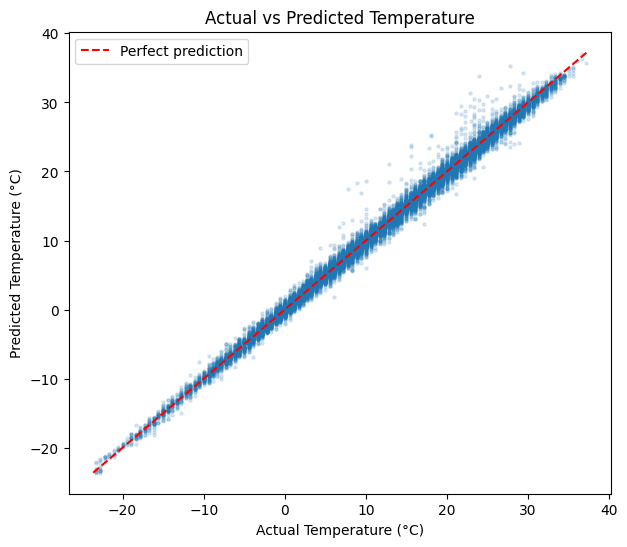

In [11]:

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    predictions,
    alpha=0.15,
    s=5
)

limits = [
    min(y_test.min(), predictions.min()),
    max(y_test.max(), predictions.max())
]

plt.plot(limits, limits, "r--", label="Perfect prediction")

plt.xlabel("Actual Temperature (°C)")
plt.ylabel("Predicted Temperature (°C)")
plt.title("Actual vs Predicted Temperature")
plt.legend()
plt.show()



### Linear Regression Results

| Model | RMSE | MAE | $R^2$ |
|---|---:|---:|---:|
| Persistence Baseline | 1.0611 | 0.7382 | 0.9912 |
| Linear Regression | 0.8379 | 0.5967 | 0.9945 |

Our linear regression model improved the MAE by 19.17% and the RMSE by 21.03% compared with the persistence baseline.

The scatter plot shows that most predictions are close to the perfect prediction line. However, we observe slightly more variation at higher temperatures.

Although our model achieved an $R^2$ of 0.9945, the baseline also performed well. This suggests that current temperature accounts for much of the predictive accuracy. The additional weather and time features provide a smaller but measurable improvement.
  

In [12]:

# Create a DataFrame for residual analysis
residual_data = pd.DataFrame({
    "actual": y_test,
    "predicted": predictions,
    "current_temp": X_test["temperature_c"],
    "month": X_test["month"],
    "hour": X_test["hour_of_day"]
}, index=y_test.index)

residual_data["residual"] = (
    residual_data["actual"] - residual_data["predicted"]
)

residual_data["absolute_error"] = residual_data["residual"].abs()

residual_data["temperature_change"] = (
    residual_data["actual"] - residual_data["current_temp"]
)

residual_data["residual"].describe()


count    17428.000000
mean         0.017624
std          0.837785
min         -9.921401
25%         -0.403202
50%          0.042010
75%          0.474898
max          4.783985
Name: residual, dtype: float64

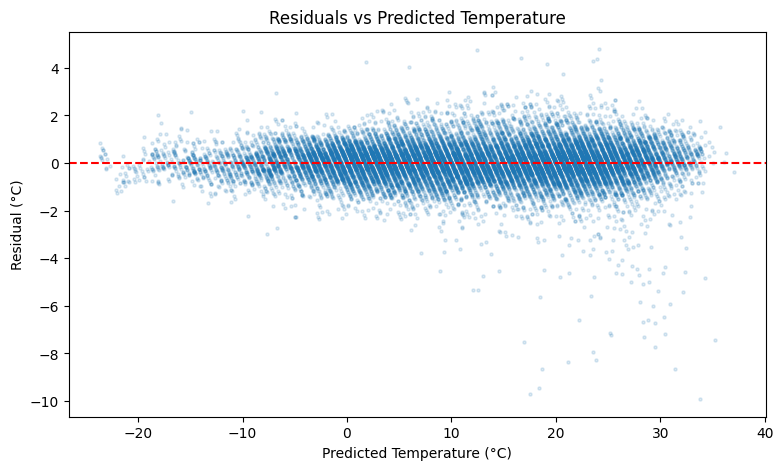

In [13]:
plt.figure(figsize=(9, 5))

plt.scatter(
    residual_data["predicted"],
    residual_data["residual"],
    alpha=0.15,
    s=5
)

plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted Temperature (°C)")
plt.ylabel("Residual (°C)")
plt.title("Residuals vs Predicted Temperature")
plt.show()


In [14]:

# Group observations by the size of hourly temperature changes
residual_data["change_group"] = pd.cut(
    residual_data["temperature_change"].abs(),
    bins=[0, 0.5, 1, 2, 3, float("inf")],
    labels=["≤0.5", "0.5–1", "1–2", "2–3", ">3"],
    include_lowest=True
)

change_results = residual_data.groupby(
    "change_group", observed=True
)["absolute_error"].agg(["mean", "count"])

change_results.columns = ["MAE", "Observations"]

display(change_results)


,MAE,Observations
change_group,,
≤0.5,0.419134,6995
0.5–1,0.426613,4601
1–2,0.718925,4739
2–3,1.548825,891
>3,3.549141,202


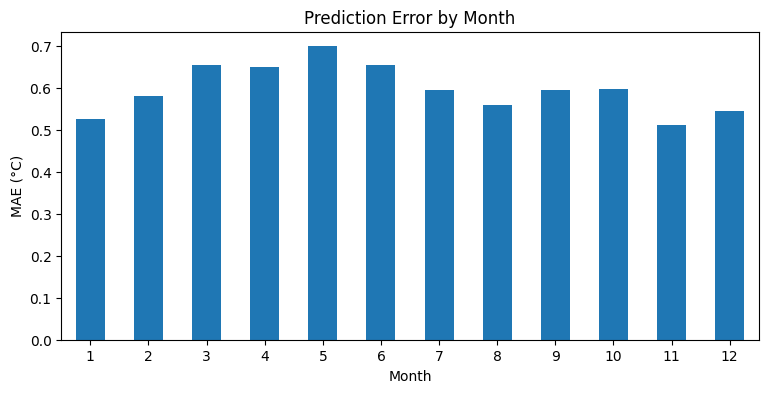

In [16]:

monthly_mae = residual_data.groupby(
    "month"
)["absolute_error"].mean()

monthly_mae.plot(
    kind="bar",
    figsize=(9, 4)
)

plt.xlabel("Month")
plt.ylabel("MAE (°C)")
plt.title("Prediction Error by Month")
plt.xticks(rotation=0)
plt.show()


In [17]:

from sklearn.model_selection import TimeSeriesSplit, cross_validate
import pandas as pd

# Ensure chronological order
X_cv = X_train.sort_index()
y_cv = y_train.loc[X_cv.index]

# Define cross-validation
tscv = TimeSeriesSplit(n_splits=5)

# Evaluation metrics
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

# Run cross-validation
scores = cross_validate(
    model,
    X_cv,
    y_cv,
    cv=tscv,
    scoring=scoring
)

# Store results
cv_results = pd.DataFrame({
    "MAE": -scores["test_MAE"],
    "RMSE": -scores["test_RMSE"],
    "R²": scores["test_R2"]
})

cv_results.index = range(1, 6)
cv_results.index.name = "Fold"

display(cv_results.round(4))


,MAE,RMSE,R²
Fold,,,
1,0.6538,0.9012,0.9935
2,0.6363,0.8940,0.9944
3,0.6204,0.8636,0.9945
4,0.5843,0.8193,0.9946
5,0.5962,0.8982,0.9933


In [18]:
cv_summary = cv_results.agg(["mean", "std"])

display(cv_summary.round(4))


,MAE,RMSE,R²
mean,0.6182,0.8753,0.9941
std,0.0284,0.0347,0.0006


In [19]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

baseline_results = []

for _, val_idx in tscv.split(X_cv):
    actual = y_cv.iloc[val_idx]
    baseline = X_cv.iloc[val_idx]["temperature_c"]

    baseline_results.append({
        "MAE": mean_absolute_error(actual, baseline),
        "RMSE": np.sqrt(mean_squared_error(actual, baseline)),
        "R²": r2_score(actual, baseline)
    })

baseline_cv = pd.DataFrame(baseline_results)

comparison = pd.DataFrame({
    "Persistence Baseline": baseline_cv.mean(),
    "Linear Regression": cv_results.mean()
}).T

display(comparison.round(4))


,MAE,RMSE,R²
Persistence Baseline,0.7368,1.0745,0.9910
Linear Regression,0.6182,0.8753,0.9941


To evaluate our multiple linear regression model, we used time-series cross-validation and compared its performance against a persistence baseline. The baseline assumes that the temperature in the next hour will remain the same as the current temperature. Our linear regression outperformed the baseline, reducing MAE from 0.7368°C to 0.6182°C and RMSE from 1.0745°C to 0.8753°C. This represents an improvement of approximately 16.1% in MAE and 18.5% in RMSE. The $R^2$ also increased from 0.9910 to 0.9941, suggesting that the additional weather variables improve our predictions beyond simply using the current temperature.

Cross-validation helps us assess overfitting by testing our model across multiple periods instead of relying on a single training and testing split. We used `TimeSeriesSplit` to preserve chronological order, ensuring that the model was trained on earlier observations and evaluated on later observations. This reduces the risk of overestimating performance due to a favorable data split and helps us determine whether the model generalizes to unseen data. Although cross-validation does not eliminate overfitting, consistent performance across the folds would provide stronger evidence that our regression model is reliable.

In [22]:
# Save the finalized modelling dataset
model_data.to_parquet(
    "model_data_weather.parquet",
    index=False
)
from sklearn.model_selection import train_test_split
import numpy as np

SEED = SEED

# Create a persistent split
train_idx, test_idx = train_test_split(
    np.arange(len(model_data)),
    test_size=0.2,
    random_state=SEED
)

# Save indices
np.savez(
    "model_split_weather.npz",
    train_idx=train_idx,
    test_idx=test_idx
)